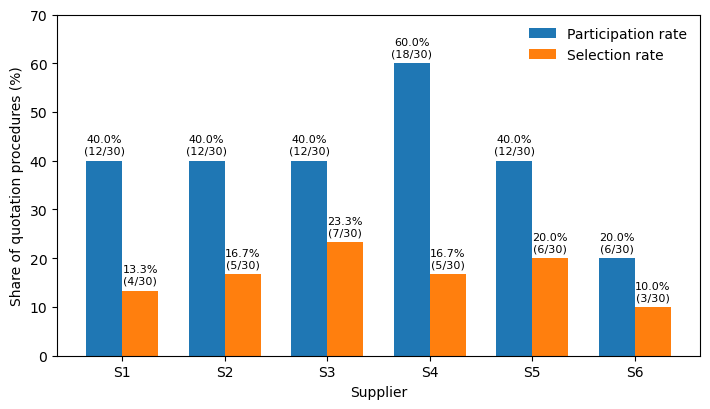

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FILE = "D:/project/thesis-object-centric-simulation/analysis/OCPA&pm4py/output/tables2/tables/BQ4_PM4Py_results.xlsx"

df = pd.read_excel(
    FILE,
    sheet_name="Supplier_Rates"
)

x = np.arange(len(df))
width = 0.35

fig, ax = plt.subplots(figsize=(7.2, 4.2))

bars1 = ax.bar(
    x - width / 2,
    df["participation_rate"] * 100,
    width,
    label="Participation rate"
)

bars2 = ax.bar(
    x + width / 2,
    df["selection_rate"] * 100,
    width,
    label="Selection rate"
)

ax.set_ylabel("Share of quotation procedures (%)")
ax.set_xlabel("Supplier")

ax.set_xticks(x)
ax.set_xticklabels(df["supplier"])

ax.set_ylim(0, 70)

ax.legend(frameon=False)

# percentage + count
for bar, count, total in zip(
    bars1,
    df["participation_count"],
    df["total_quotation_procedures"]
):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 1,
        f"{h:.1f}%\n({count}/{total})",
        ha="center",
        va="bottom",
        fontsize=8
    )

for bar, count, total in zip(
    bars2,
    df["selection_count"],
    df["total_quotation_procedures"]
):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 1,
        f"{h:.1f}%\n({count}/{total})",
        ha="center",
        va="bottom",
        fontsize=8
    )

fig.tight_layout()

fig.savefig(
    "D:/project/thesis-object-centric-simulation/analysis/OCPA&pm4py/output/figures/supplier_participation_selection.pdf",
    bbox_inches="tight"
)

fig.savefig(
    "D:/project/thesis-object-centric-simulation/analysis/OCPA&pm4py/output/figures/supplier_participation_selection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()